# Z expectation value versus circuit layers

The seven experiment cells build circuits with **1, 5, 10, 15, 20, 25, and 30 layers**. Each uses one circuit (can average for many random circuits later), prints its measured $\langle Z_0\rangle$, saves that value in `results`, and displays the complete circuit.

**Gates in each layer:** fresh random RX and RY rotations on every qubit, with angles between −π/4 and +π/4 (−45° to +45°). Then RZZ(π/4) entangling gates act on neighboring pairs: (0,1), (2,3), (4,5) in the first layer; (1,2), (3,4) in the second; repeat that alternating pattern. 

Each cell restarts the gate generator with the same `seed`, so the longer circuits contain the same early gates as the shorter ones. All circuits start in $|000000\rangle$. A single circuit's Z can fluctuate or become negative; a perfectly smooth decline is not guaranteed.

One shot means preparing the initial state, applying this circuit, and measuring qubit 0 once. `shots = 1024` gives 1024 outcomes for that same circuit. Assign +1 to a measured 0 and −1 to a measured 1:

$$\langle Z_0\rangle\approx\frac{N_0-N_1}{1024}.$$

For example, 768 zeros and 256 ones give 0.5. More shots reduce measurement noise; they do not add layers or new random circuits. With 1024 shots, the sampling standard error is at most about 0.031. [Qiskit sampler documentation](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.primitives.StatevectorSampler)

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from qiskit import QuantumCircuit
from qiskit.primitives import StatevectorSampler

n_qubits = 6 #can be increased but will require more shots to get a good estimate of the expectation value
shots = 1024
seed = 2026
rotation_limit = np.pi / 4  # Maximum RX/RY angle: 45 degrees, in radians.
entangling_angle = np.pi / 4  # RZZ interaction angle: 45 degrees.

results = {}  # Maps each total number of layers to its measured Z value.

Manasa's plotting function below

In [3]:
# ----- PLOTTING: keep this section when replacing the data -----

def plot_expectation_values(depths, values, placeholder=True, output_path="thermalization_plot.png"):
    depths = np.asarray(depths, dtype=float)
    values = np.asarray(values, dtype=float)

    if depths.ndim != 1 or values.ndim != 1:
        raise ValueError("Depths and expectation values must be 1D arrays.")

    if len(depths) == 0 or len(depths) != len(values):
        raise ValueError("Provide the same nonzero number of depths and values.")

    if not np.all(np.isfinite(depths)) or not np.all(np.isfinite(values)):
        raise ValueError("All data must contain finite numbers.")

    if np.any(depths < 0):
        raise ValueError("Circuit depths cannot be negative.")

    if np.any((values < -1) | (values > 1)):
        raise ValueError("Pauli-Z expectation values must be between -1 and 1.")

    # Arrange points in increasing circuit-depth order.
    order = np.argsort(depths)
    depths = depths[order]
    values = values[order]

    fig, ax = plt.subplots(figsize=(9, 5)) # creates a graph and a set of subplots with a specified size

    # --- This is all graph styling and labeling, not quantum-circuit code. ---
    # Draws data points and connects them with lines
    ax.plot(
        depths,
        values,
        color="#0099AB",
        linewidth=2,
        marker="o",
        markersize=4,
        label="Synthetic placeholder data" if placeholder else "Circuit data",
    )

    ax.axhline(0, color="gray", linestyle="--", linewidth=1)

    ax.set_xlabel("Circuit depth", fontsize=12)
    ax.set_ylabel(
        r"Pauli-$Z$ expectation value $\langle Z\rangle$",
        fontsize=12,
    )
    ax.set_title(
        "Illustrative Relaxation — Placeholder Data"
        if placeholder
        else "Pauli-Z Expectation Value vs. Circuit Depth"
    )

    ax.set_ylim(-1.05, 1.05)
    ax.grid(alpha=0.25)
    ax.legend()

    fig.tight_layout()
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()

## 1 layer

1 layer(s): <Z_0> = +0.859375; counts = {'0': 952, '1': 72}


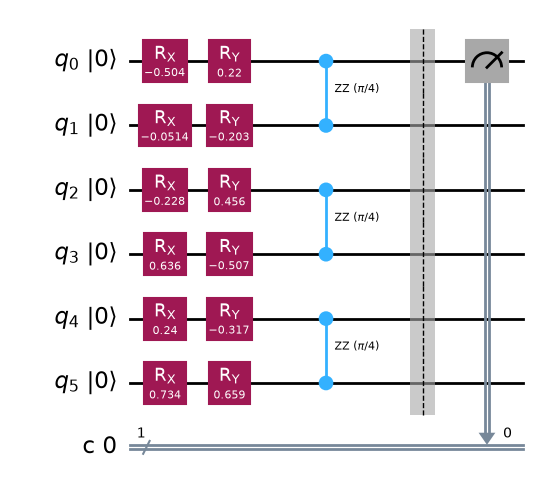

In [4]:
layers = 1  # Change this to any positive integer.
if type(layers) is not int or layers < 1:
    raise ValueError("layers must be an integer starting from 1")

rng = np.random.default_rng(seed)
qc = QuantumCircuit(n_qubits, 1)  # Starts in |000000>; c[0] stores one measured bit.

for layer_index in range(layers):
    for q in range(n_qubits):
        # RX and RY are single-qubit rotations; draw a fresh angle for each gate.
        qc.rx(rng.uniform(-rotation_limit, rotation_limit), q)
        qc.ry(rng.uniform(-rotation_limit, rotation_limit), q)

    # RZZ couples neighboring qubits and can entangle their superpositions.
    # Alternate (0,1),(2,3),(4,5) with (1,2),(3,4) in successive layers.
    for q in range(layer_index % 2, n_qubits - 1, 2):
        qc.rzz(entangling_angle, q, q + 1)
    qc.barrier()  # A visual layer boundary; it does not change the state.

qc.measure(0, 0)  # Measure only qubit 0, after all layers have been applied.
sampler = StatevectorSampler(seed=seed + layers)  # Reproducible shot samples.
counts = sampler.run([qc], shots=shots).result()[0].data.c.get_counts()
z = (counts.get("0", 0) - counts.get("1", 0)) / shots
results[layers] = z  # Rerunning this depth replaces its previous result.

print(f"{layers} layer(s): <Z_0> = {z:+.6f}; counts = {counts}")
fig = qc.draw(output="mpl", fold=18, initial_state=True)
display(fig)  # Long circuits wrap onto more rows; no gates are omitted.
plt.close(fig)

## 5 layers

5 layer(s): <Z_0> = +0.941406; counts = {'0': 994, '1': 30}


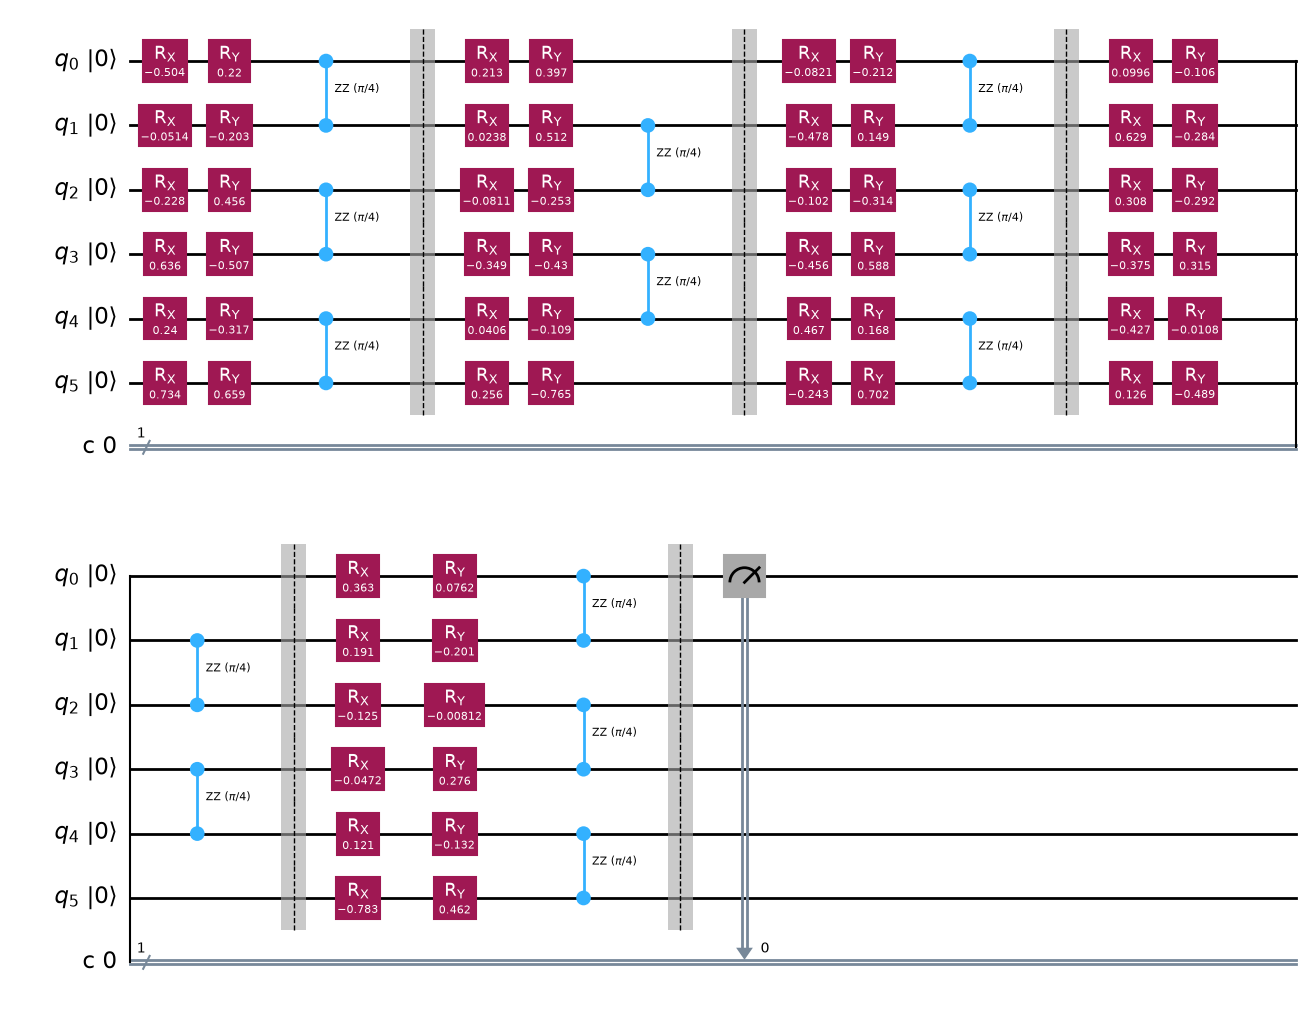

In [5]:
layers = 5  # Change this to any positive integer.
if type(layers) is not int or layers < 1:
    raise ValueError("layers must be an integer starting from 1")

rng = np.random.default_rng(seed)
qc = QuantumCircuit(n_qubits, 1)  # Starts in |000000>; c[0] stores one measured bit.

for layer_index in range(layers):
    for q in range(n_qubits):
        # RX and RY are single-qubit rotations; draw a fresh angle for each gate.
        qc.rx(rng.uniform(-rotation_limit, rotation_limit), q)
        qc.ry(rng.uniform(-rotation_limit, rotation_limit), q)

    # RZZ couples neighboring qubits and can entangle their superpositions.
    # Alternate (0,1),(2,3),(4,5) with (1,2),(3,4) in successive layers.
    for q in range(layer_index % 2, n_qubits - 1, 2):
        qc.rzz(entangling_angle, q, q + 1)
    qc.barrier()  # A visual layer boundary; it does not change the state.

qc.measure(0, 0)  # Measure only qubit 0, after all layers have been applied.
sampler = StatevectorSampler(seed=seed + layers)  # Reproducible shot samples.
counts = sampler.run([qc], shots=shots).result()[0].data.c.get_counts()
z = (counts.get("0", 0) - counts.get("1", 0)) / shots
results[layers] = z  # Rerunning this depth replaces its previous result.

print(f"{layers} layer(s): <Z_0> = {z:+.6f}; counts = {counts}")
fig = qc.draw(output="mpl", fold=18, initial_state=True)
display(fig)  # Long circuits wrap onto more rows; no gates are omitted.
plt.close(fig)

## 10 layers

10 layer(s): <Z_0> = +0.636719; counts = {'1': 186, '0': 838}


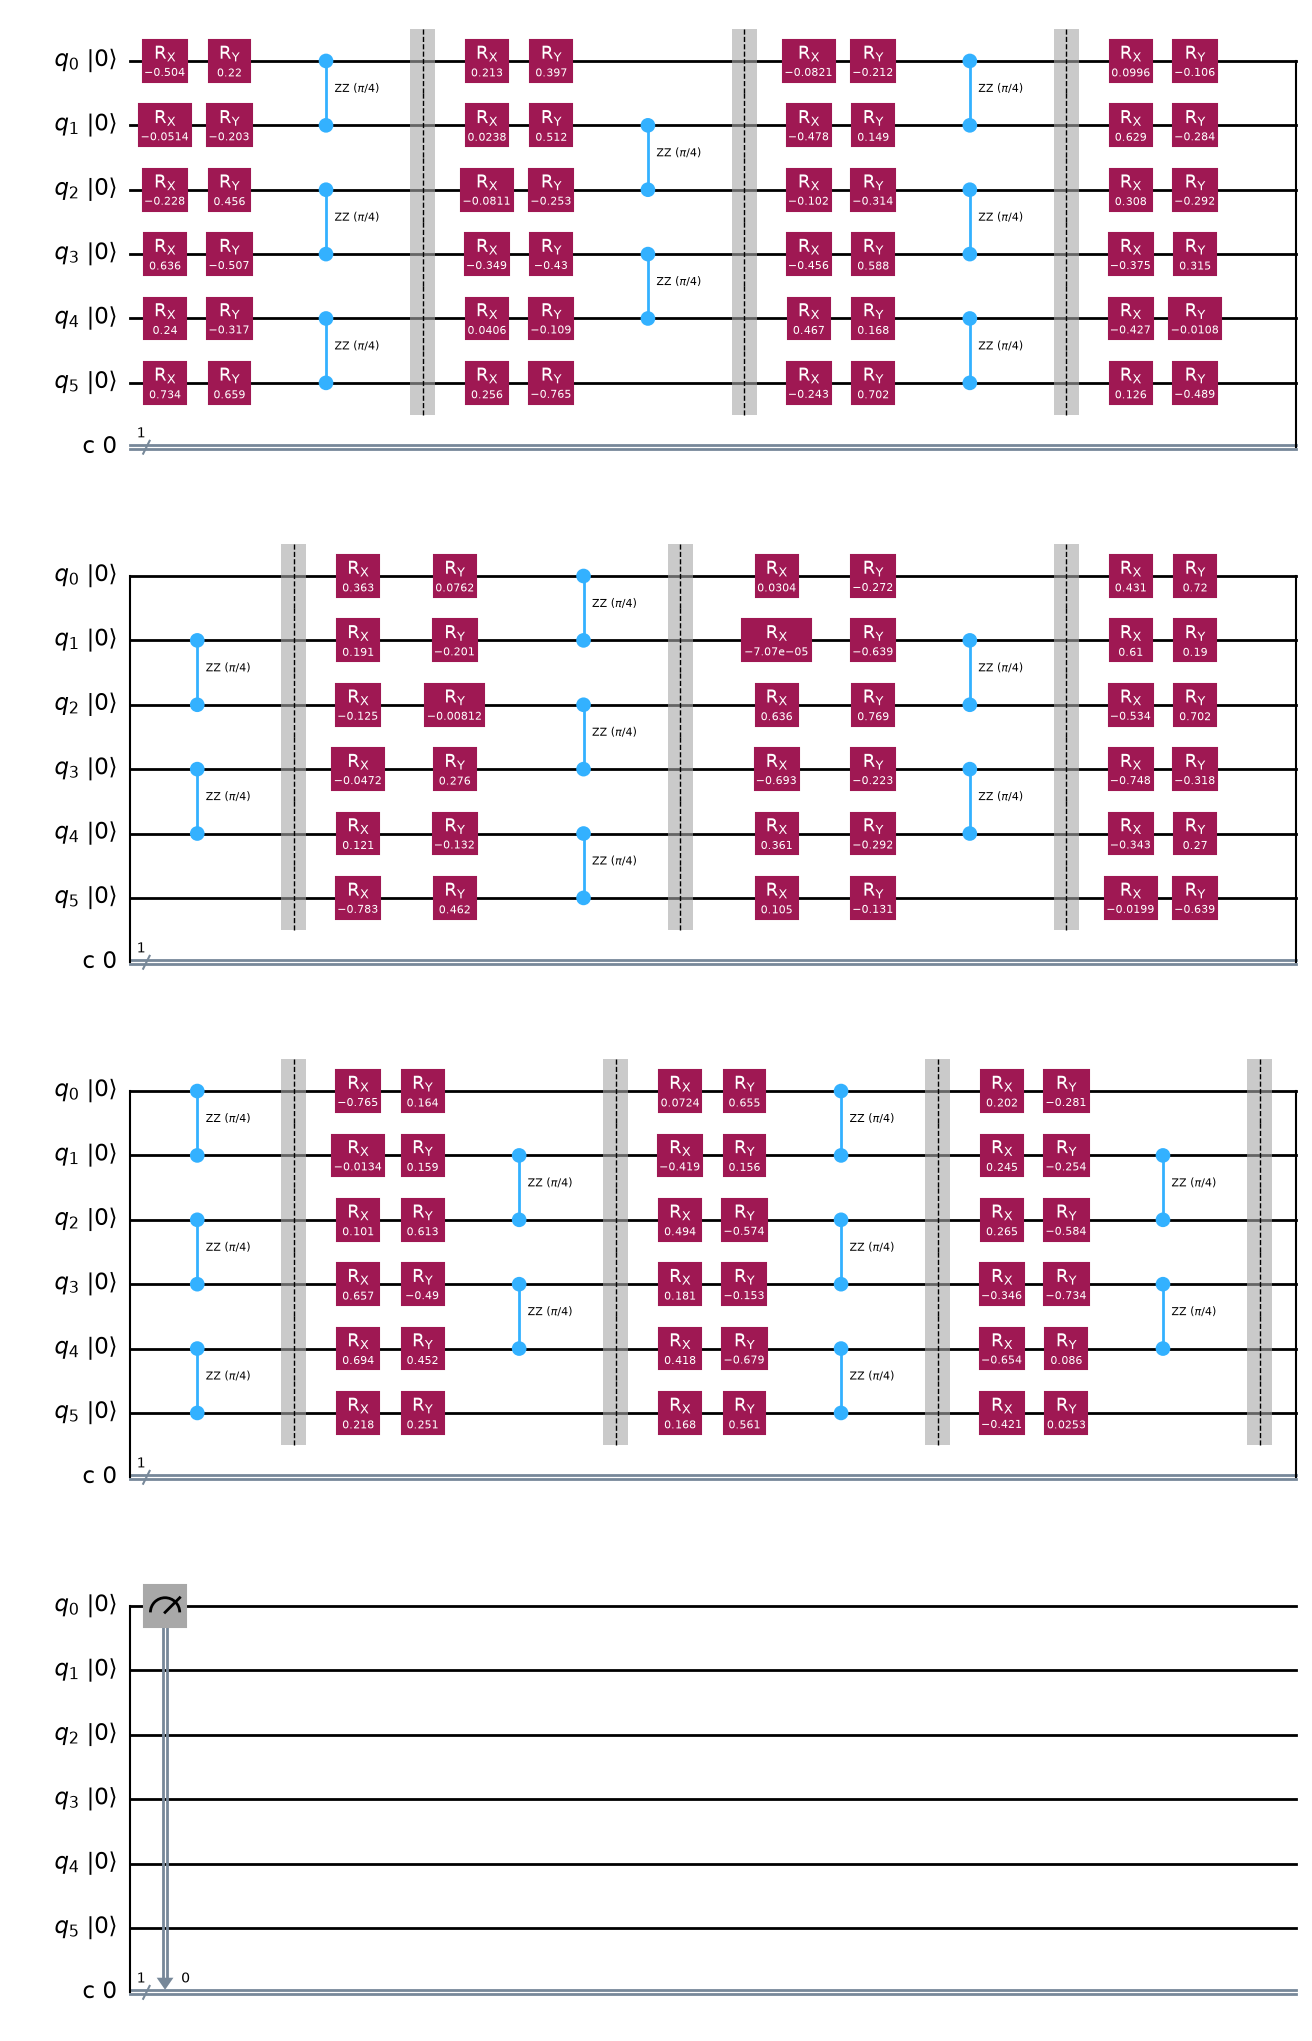

In [6]:
layers = 10  # Change this to any positive integer.
if type(layers) is not int or layers < 1:
    raise ValueError("layers must be an integer starting from 1")

rng = np.random.default_rng(seed)
qc = QuantumCircuit(n_qubits, 1)  # Starts in |000000>; c[0] stores one measured bit.

for layer_index in range(layers):
    for q in range(n_qubits):
        # RX and RY are single-qubit rotations; draw a fresh angle for each gate.
        qc.rx(rng.uniform(-rotation_limit, rotation_limit), q)
        qc.ry(rng.uniform(-rotation_limit, rotation_limit), q)

    # RZZ couples neighboring qubits and can entangle their superpositions.
    # Alternate (0,1),(2,3),(4,5) with (1,2),(3,4) in successive layers.
    for q in range(layer_index % 2, n_qubits - 1, 2):
        qc.rzz(entangling_angle, q, q + 1)
    qc.barrier()  # A visual layer boundary; it does not change the state.

qc.measure(0, 0)  # Measure only qubit 0, after all layers have been applied.
sampler = StatevectorSampler(seed=seed + layers)  # Reproducible shot samples.
counts = sampler.run([qc], shots=shots).result()[0].data.c.get_counts()
z = (counts.get("0", 0) - counts.get("1", 0)) / shots
results[layers] = z  # Rerunning this depth replaces its previous result.

print(f"{layers} layer(s): <Z_0> = {z:+.6f}; counts = {counts}")
fig = qc.draw(output="mpl", fold=18, initial_state=True)
display(fig)  # Long circuits wrap onto more rows; no gates are omitted.
plt.close(fig)

## 15 layers

15 layer(s): <Z_0> = +0.613281; counts = {'0': 826, '1': 198}


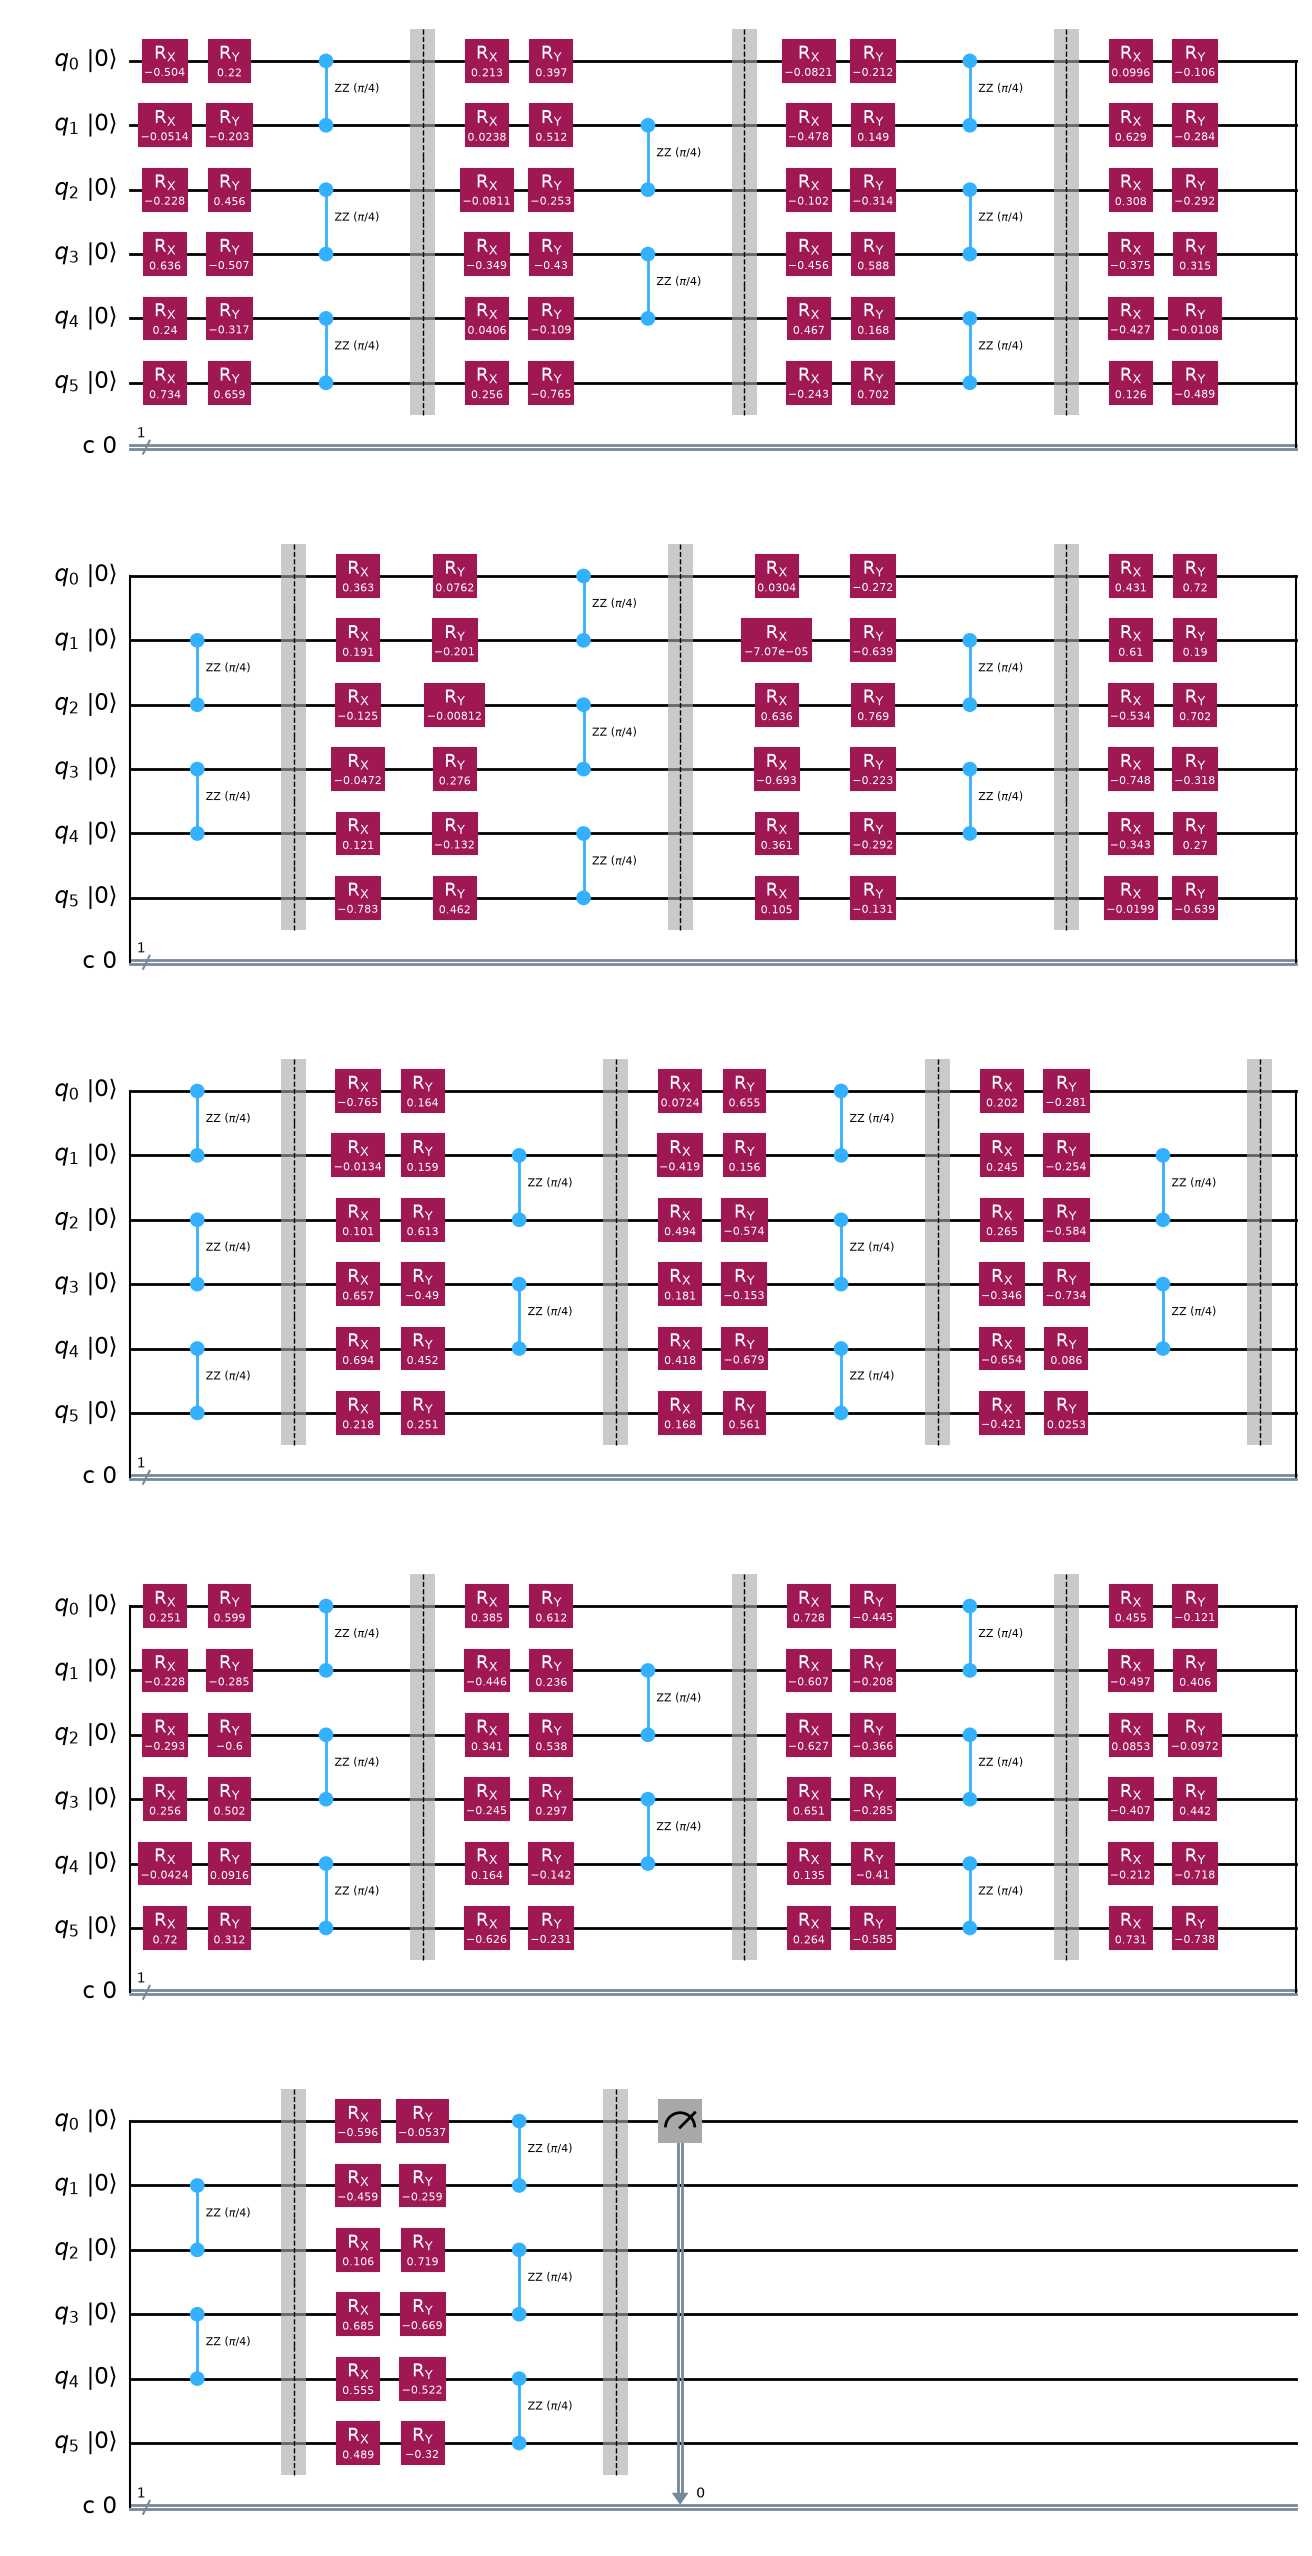

In [7]:
layers = 15  # Change this to any positive integer.
if type(layers) is not int or layers < 1:
    raise ValueError("layers must be an integer starting from 1")

rng = np.random.default_rng(seed)
qc = QuantumCircuit(n_qubits, 1)  # Starts in |000000>; c[0] stores one measured bit.

for layer_index in range(layers):
    for q in range(n_qubits):
        # RX and RY are single-qubit rotations; draw a fresh angle for each gate.
        qc.rx(rng.uniform(-rotation_limit, rotation_limit), q)
        qc.ry(rng.uniform(-rotation_limit, rotation_limit), q)

    # RZZ couples neighboring qubits and can entangle their superpositions.
    # Alternate (0,1),(2,3),(4,5) with (1,2),(3,4) in successive layers.
    for q in range(layer_index % 2, n_qubits - 1, 2):
        qc.rzz(entangling_angle, q, q + 1)
    qc.barrier()  # A visual layer boundary; it does not change the state.

qc.measure(0, 0)  # Measure only qubit 0, after all layers have been applied.
sampler = StatevectorSampler(seed=seed + layers)  # Reproducible shot samples.
counts = sampler.run([qc], shots=shots).result()[0].data.c.get_counts()
z = (counts.get("0", 0) - counts.get("1", 0)) / shots
results[layers] = z  # Rerunning this depth replaces its previous result.

print(f"{layers} layer(s): <Z_0> = {z:+.6f}; counts = {counts}")
fig = qc.draw(output="mpl", fold=18, initial_state=True)
display(fig)  # Long circuits wrap onto more rows; no gates are omitted.
plt.close(fig)

## 20 layers

In [8]:
layers = 20  # Change this to any positive integer.
if type(layers) is not int or layers < 1:
    raise ValueError("layers must be an integer starting from 1")

rng = np.random.default_rng(seed)
qc = QuantumCircuit(n_qubits, 1)  # Starts in |000000>; c[0] stores one measured bit.

for layer_index in range(layers):
    for q in range(n_qubits):
        # RX and RY are single-qubit rotations; draw a fresh angle for each gate.
        qc.rx(rng.uniform(-rotation_limit, rotation_limit), q)
        qc.ry(rng.uniform(-rotation_limit, rotation_limit), q)

    # RZZ couples neighboring qubits and can entangle their superpositions.
    # Alternate (0,1),(2,3),(4,5) with (1,2),(3,4) in successive layers.
    for q in range(layer_index % 2, n_qubits - 1, 2):
        qc.rzz(entangling_angle, q, q + 1)
    qc.barrier()  # A visual layer boundary; it does not change the state.

qc.measure(0, 0)  # Measure only qubit 0, after all layers have been applied.
sampler = StatevectorSampler(seed=seed + layers)  # Reproducible shot samples.
counts = sampler.run([qc], shots=shots).result()[0].data.c.get_counts()
z = (counts.get("0", 0) - counts.get("1", 0)) / shots
results[layers] = z  # Rerunning this depth replaces its previous result.

print(f"{layers} layer(s): <Z_0> = {z:+.6f}; counts = {counts}")

20 layer(s): <Z_0> = -0.257812; counts = {'1': 644, '0': 380}


## 25 layers

In [9]:
layers = 25  # Change this to any positive integer.
if type(layers) is not int or layers < 1:
    raise ValueError("layers must be an integer starting from 1")

rng = np.random.default_rng(seed)
qc = QuantumCircuit(n_qubits, 1)  # Starts in |000000>; c[0] stores one measured bit.

for layer_index in range(layers):
    for q in range(n_qubits):
        # RX and RY are single-qubit rotations; draw a fresh angle for each gate.
        qc.rx(rng.uniform(-rotation_limit, rotation_limit), q)
        qc.ry(rng.uniform(-rotation_limit, rotation_limit), q)

    # RZZ couples neighboring qubits and can entangle their superpositions.
    # Alternate (0,1),(2,3),(4,5) with (1,2),(3,4) in successive layers.
    for q in range(layer_index % 2, n_qubits - 1, 2):
        qc.rzz(entangling_angle, q, q + 1)
    qc.barrier()  # A visual layer boundary; it does not change the state.

qc.measure(0, 0)  # Measure only qubit 0, after all layers have been applied.
sampler = StatevectorSampler(seed=seed + layers)  # Reproducible shot samples.
counts = sampler.run([qc], shots=shots).result()[0].data.c.get_counts()
z = (counts.get("0", 0) - counts.get("1", 0)) / shots
results[layers] = z  # Rerunning this depth replaces its previous result.

print(f"{layers} layer(s): <Z_0> = {z:+.6f}; counts = {counts}")

25 layer(s): <Z_0> = -0.355469; counts = {'1': 694, '0': 330}


## 30 layers

In [10]:
layers = 30  # Change this to any positive integer.
if type(layers) is not int or layers < 1:
    raise ValueError("layers must be an integer starting from 1")

rng = np.random.default_rng(seed)
qc = QuantumCircuit(n_qubits, 1)  # Starts in |000000>; c[0] stores one measured bit.

for layer_index in range(layers):
    for q in range(n_qubits):
        # RX and RY are single-qubit rotations; draw a fresh angle for each gate.
        qc.rx(rng.uniform(-rotation_limit, rotation_limit), q)
        qc.ry(rng.uniform(-rotation_limit, rotation_limit), q)

    # RZZ couples neighboring qubits and can entangle their superpositions.
    # Alternate (0,1),(2,3),(4,5) with (1,2),(3,4) in successive layers.
    for q in range(layer_index % 2, n_qubits - 1, 2):
        qc.rzz(entangling_angle, q, q + 1)
    qc.barrier()  # A visual layer boundary; it does not change the state.

qc.measure(0, 0)  # Measure only qubit 0, after all layers have been applied.
sampler = StatevectorSampler(seed=seed + layers)  # Reproducible shot samples.
counts = sampler.run([qc], shots=shots).result()[0].data.c.get_counts()
z = (counts.get("0", 0) - counts.get("1", 0)) / shots
results[layers] = z  # Rerunning this depth replaces its previous result.

print(f"{layers} layer(s): <Z_0> = {z:+.6f}; counts = {counts}")

30 layer(s): <Z_0> = -0.189453; counts = {'1': 609, '0': 415}


## Plot the measured values

This uses one measured value per completed experiment cell. There is no synthetic data, smoothing, or average over random circuits. Rerunning a depth updates its existing point; changing `layers` to a new value adds a point. Rerun the setup cell to clear `results` before starting a fresh set of experiments.

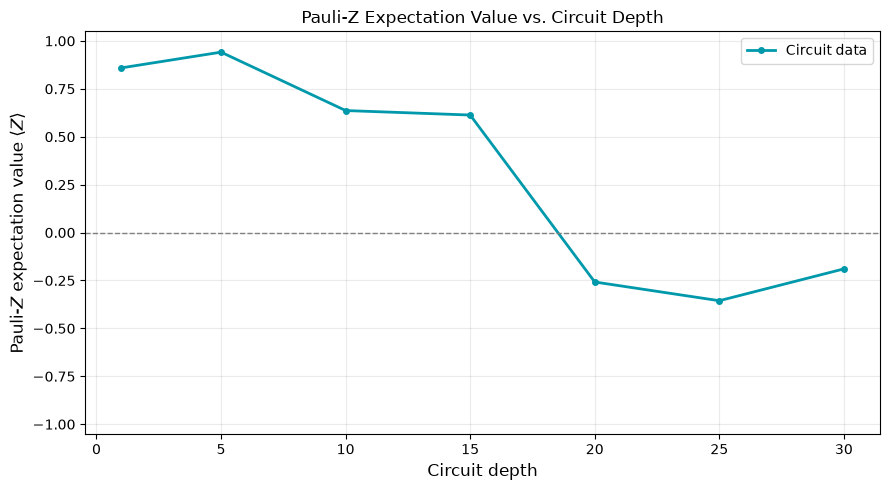

In [11]:
# Replace the original placeholder arrays with the stored circuit results.
circuit_depths = np.array(sorted(results))
expectation_values = np.array([results[depth] for depth in circuit_depths])
using_placeholder_data = False

plot_expectation_values(
    circuit_depths,
    expectation_values,
    placeholder=using_placeholder_data,
)

# Natural thermalization for circuit with one qubit left untouched

## Sweep over circuit layers

Run the setup and plotting-function cells above first. Edit `layers` below to choose the depths. Each depth starts from a fresh circuit, leaves the last qubit (`q_5` for six qubits) untouched, and measures qubit 0. Each layer applies RX/RY rotations to the active qubits, followed by alternating RZZ pairs: (0,1), (2,3), then (1,2), (3,4).

Only the 1- and 5-layer circuits are displayed; expectation values are printed for every depth. Restarting the gate generator for each depth keeps the same early gates across depths. `untouched_results` is reset on every sweep and stores these measurements separately from the earlier experiment.


1 layer(s): <Z_0> = +0.859375; counts = {'0': 952, '1': 72}


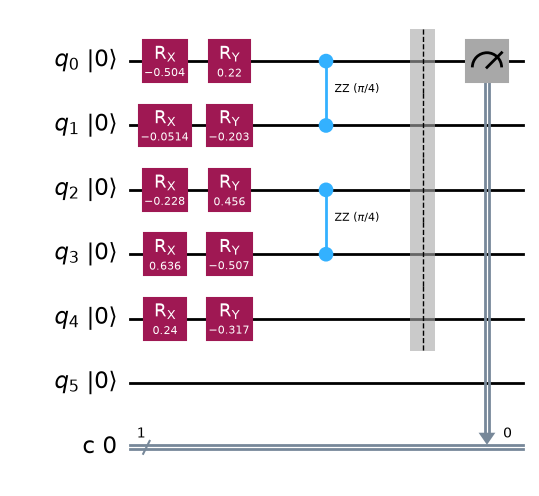

5 layer(s): <Z_0> = +0.765625; counts = {'0': 904, '1': 120}


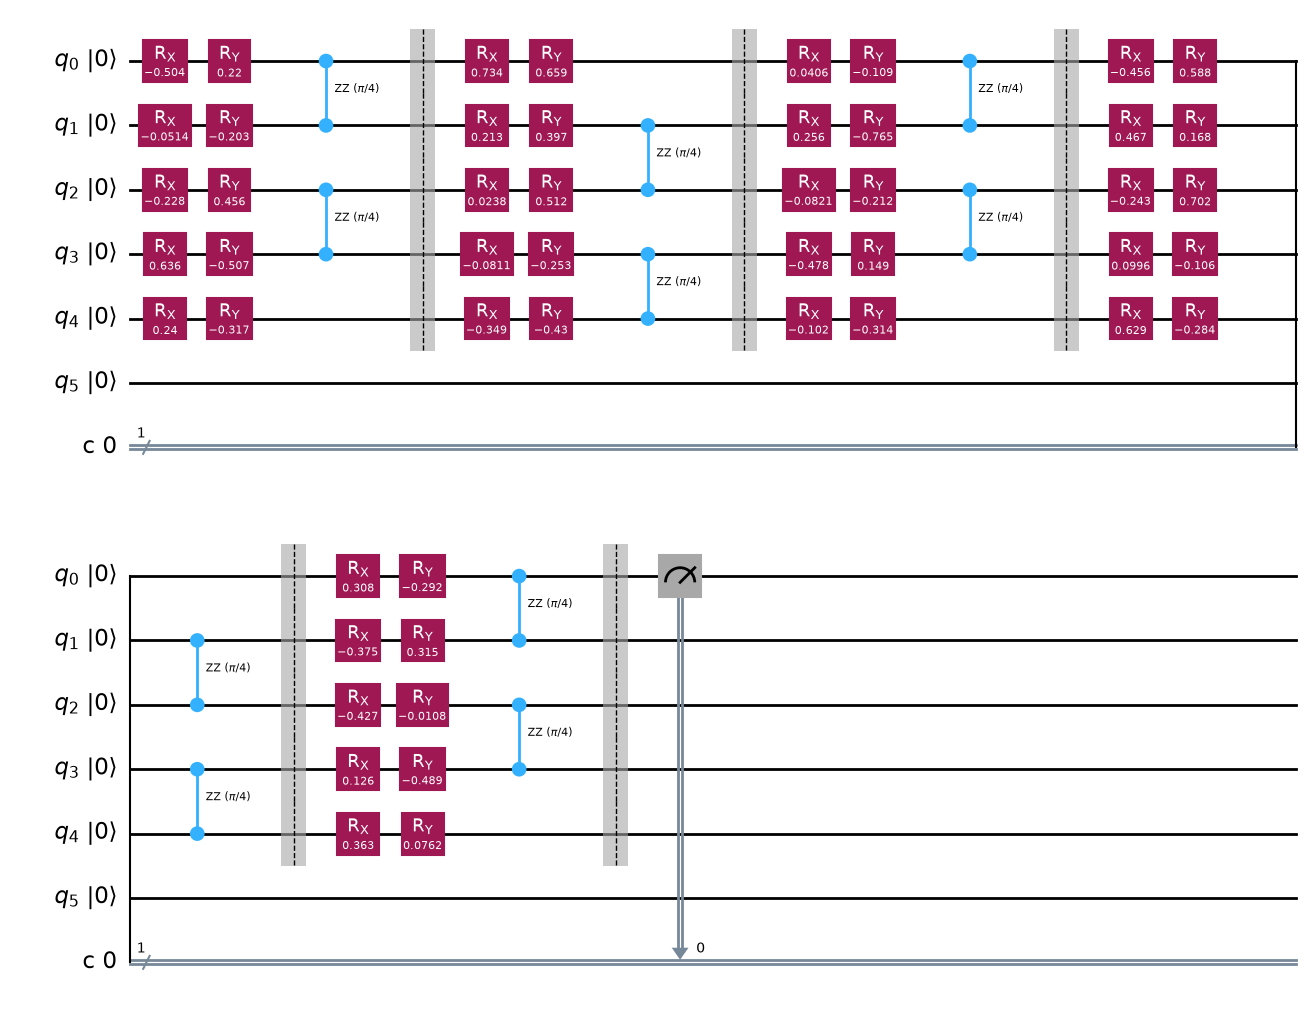

10 layer(s): <Z_0> = +0.521484; counts = {'1': 245, '0': 779}
15 layer(s): <Z_0> = -0.433594; counts = {'1': 734, '0': 290}
20 layer(s): <Z_0> = -0.457031; counts = {'1': 746, '0': 278}
25 layer(s): <Z_0> = -0.320312; counts = {'1': 676, '0': 348}
30 layer(s): <Z_0> = -0.429688; counts = {'1': 732, '0': 292}


In [12]:
layers = [1, 5, 10, 15, 20, 25, 30]  # Choose any nonempty list of positive integers.
if not layers or any(type(depth) is not int or depth < 1 for depth in layers):
    raise ValueError("layers must contain positive integers starting from 1")

untouched_results = {}  # Start a fresh sweep for the untouched-qubit experiment.

for depth in layers:
    rng = np.random.default_rng(seed)
    qc = QuantumCircuit(n_qubits, 1)  # Fresh all-zero state for each depth.

    for layer_index in range(depth):
        for q in range(n_qubits - 1):  # Leave the last qubit untouched.
            # Draw a fresh angle for every RX and RY gate.
            qc.rx(rng.uniform(-rotation_limit, rotation_limit), q)
            qc.ry(rng.uniform(-rotation_limit, rotation_limit), q)

        # Alternate neighboring pairs, excluding the last qubit in every layer.
        for q in range(layer_index % 2, n_qubits - 2, 2):
            qc.rzz(entangling_angle, q, q + 1)
        qc.barrier(*range(n_qubits - 1))  # Visual boundary on the active qubits.

    qc.measure(0, 0)  # Measure qubit 0 after this circuit's final layer.
    sampler = StatevectorSampler(seed=seed + depth)
    counts = sampler.run([qc], shots=shots).result()[0].data.c.get_counts()
    z = (counts.get("0", 0) - counts.get("1", 0)) / shots
    untouched_results[depth] = z

    print(f"{depth} layer(s): <Z_0> = {z:+.6f}; counts = {counts}")
    if depth in (1, 5):
        fig = qc.draw(output="mpl", fold=18, initial_state=True)
        display(fig)
        plt.close(fig)


## Plot the untouched-qubit results

Use the same plotting function with one measured value per depth. As above, circuit depth is the number of RX/RY + RZZ layers. Rerun this cell after changing the sweep.

The plot is saved as `thermalization_plot_untouched_qubit.png`.


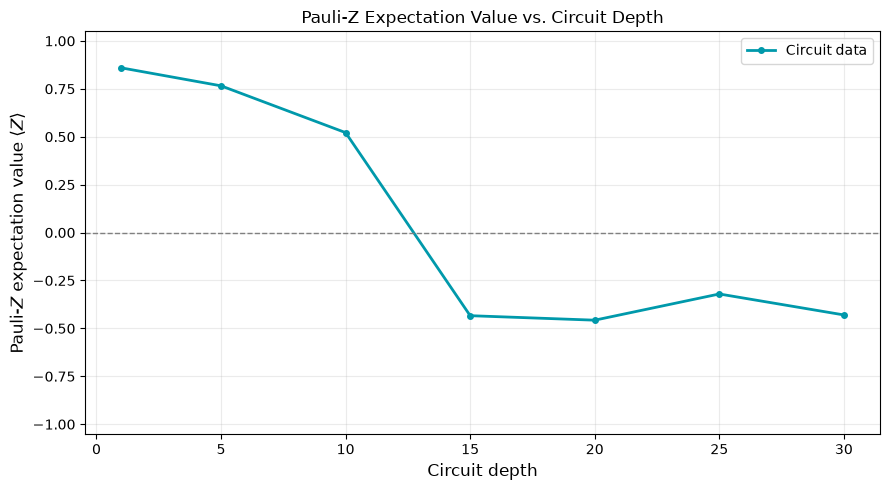

In [13]:
untouched_depths = np.array(sorted(untouched_results))
untouched_expectation_values = np.array(
    [untouched_results[depth] for depth in untouched_depths]
)

plot_expectation_values(
    untouched_depths,
    untouched_expectation_values,
    placeholder=False,
    output_path="thermalization_plot_untouched_qubit.png",
)
